10 . Implementing Self-Organizing Maps (SOM) for Image Compression-  
a. Implement Kohonen’s Self-Organizing Map (SOM) for image compression.  
b. Train SOM to reduce the number of colors in an image.  
c. Display the original and compressed images to analyze quality loss  

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from minisom import MiniSom
from sklearn.preprocessing import MinMaxScaler
from PIL import Image

In [4]:
img = Image.open('bird.jpg').convert("RGB")
pixels = np.array(img)
h, w, c = pixels.shape
pixels = pixels.reshape(-1, 3)
scaler = MinMaxScaler()
pixels_scaled = scaler.fit_transform(pixels)

In [5]:
som = MiniSom(
    4, 4, 3,
    sigma=1,
    learning_rate=0.5,
    random_seed=42
)

In [6]:
som.random_weights_init(pixels_scaled)
som.train_random(pixels_scaled, 1000)
weights = som.get_weights().reshape(-1, 3)

In [7]:
compressed_pixels = []

for pixel in pixels_scaled :
    distance = np.sqrt(np.sum((weights - pixel) ** 2, axis=1))
    nearest = np.argmin(distance)
    compressed_pixels.append(weights[nearest])

compressed_pixels = np.array(compressed_pixels)
compressed_pixels = scaler.inverse_transform(compressed_pixels)
compressed_pixels = np.clip(compressed_pixels, 0, 255)
compressed_pixels = compressed_pixels.astype(np.uint8)

compressed_image = compressed_pixels.reshape(h, w, 3)

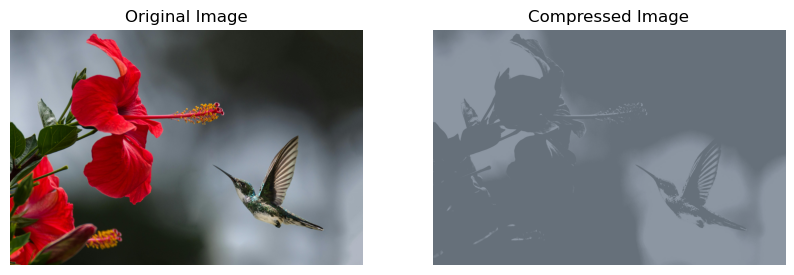

In [8]:
plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(img)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Compressed Image")
plt.imshow(compressed_image)
plt.axis("off")

plt.show()

1. What is SOM?  
SOM stands for Self-Organizing Map. It is an unsupervised neural network used to group similar data based on their features.

2. What is the main purpose of this experiment?  
To reduce the number of colors in an image using SOM while maintaining its overall appearance.

3. What is BMU?  
BMU stands for Best Matching Unit. It is the neuron having the minimum distance from the input pixel.

4. What is the main disadvantage of SOM image compression?  
It can cause loss of image quality because multiple original colors are replaced with fewer representative colors.

5. What is MiniSom?  
MiniSom is a lightweight Python library used to implement Self-Organizing Maps.